# Link Prediction in the GitHub Developer Network
### Social Network Analysis — AAT Project

**Goal:** recommend which GitHub developers should follow each other, using only the structure of the
follower network, and compare four classic link-prediction heuristics.

| Stage | Notebook section |
|---|---|
| 1. Problem definition & network modeling | §1 |
| 2. Data preparation & network construction | §2 |
| 3. SNA analysis & link prediction (CN, Jaccard, Adamic-Adar, PA) | §3 |
| 4. Algorithm comparison & validation (Precision@K, Recall, F1, ROC-AUC) | §4 |
| 5. Recommendation & interpretation (Top-10 / Top-20, filtering) | §5 |
| 6. Visualisation (figures, Cytoscape exports, interactive HTML) | §6 |

Run all cells top to bottom (about 3–4 minutes). Every random step uses seed 42, so results are reproducible.
Inputs are read from `../2_Network_Dataset_Package/data_raw/`; everything produced is written to `outputs/`.

In [1]:
import json, math, os, random, time
import numpy as np, pandas as pd, networkx as nx
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, precision_recall_curve
from IPython.display import display
%matplotlib inline
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
for d in ["outputs/dataset_package", "outputs/results", "outputs/figures", "outputs/cytoscape"]:
    os.makedirs(d, exist_ok=True)
print("networkx", nx.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

networkx 3.7 | pandas 3.0.5 | numpy 2.5.3


## 1. Problem definition & network modeling

**Problem.** GitHub developers follow each other, but each developer sees only a tiny part of the community.
Given the current mutual-follower network, predict which *unconnected* pairs of developers are most likely to
connect next, and turn the strongest predictions into "developers you may want to follow" recommendations.

**Domain:** online developer collaboration (GitHub). **Dataset:** MUSAE GitHub Social Network
(Rozemberczki, Allen & Sarkar, 2019), collected from the public GitHub API in June 2019.

| Network element | Mapping |
|---|---|
| Node | A GitHub developer (with ≥ 10 starred repositories) |
| Node attribute | `community`: web developer or machine-learning developer |
| Edge | Mutual follower relationship |
| Graph type | Undirected, unweighted, simple |

**Link prediction formulation.** Hide 20% of the edges, score every candidate pair on the remaining 80% with a
similarity heuristic, and measure how well the scores rank the hidden (real) edges above non-edges.

In [2]:
raw_edges = pd.read_csv("../2_Network_Dataset_Package/data_raw/git_edges.csv")
raw_nodes = pd.read_csv("../2_Network_Dataset_Package/data_raw/git_target.csv")
display(raw_edges.head(), raw_nodes.head())
G0 = nx.from_pandas_edgelist(raw_edges, "id_1", "id_2")
deg0 = np.array([d for _, d in G0.degree()])
print(f"nodes={G0.number_of_nodes():,}  edges={G0.number_of_edges():,}  density={nx.density(G0):.6f}")
print(f"degree: mean={deg0.mean():.2f} median={np.median(deg0):.0f} max={deg0.max():,}")
print("community sizes:", raw_nodes.ml_target.map({0: "web", 1: "ml"}).value_counts().to_dict())

,id_1,id_2
0,0,23977
1,1,34526
2,1,2370
3,1,14683
4,1,29982


,id,name,ml_target
0,0,Eiryyy,0
1,1,shawflying,0
2,2,JpMCarrilho,1
3,3,SuhwanCha,0
4,4,sunilangadi2,1


nodes=37,700  edges=289,003  density=0.000407
degree: mean=15.33 median=6 max=9,458
community sizes: {'web': 27961, 'ml': 9739}


## 2. Data preparation & network construction
Cleaning → NetworkX graph → 80/20 train–test split that keeps the training graph connected (a random spanning
tree is always kept in train) → negative sampling (one random non-edge per test edge).

In [3]:
import json
import os
import random

import networkx as nx
import numpy as np
import pandas as pd

SEED = 42
TEST_FRAC = 0.20
RAW = "../2_Network_Dataset_Package/data_raw"
OUT = "outputs/dataset_package"

random.seed(SEED)
np.random.seed(SEED)
os.makedirs(OUT, exist_ok=True)
log = {}

In [4]:
# 1. Load ---------------------------------------------------------------
edges_raw = pd.read_csv(f"{RAW}/git_edges.csv")
nodes_raw = pd.read_csv(f"{RAW}/git_target.csv")
log["raw_edges"] = len(edges_raw)
log["raw_nodes"] = len(nodes_raw)

In [5]:
# 2. Clean --------------------------------------------------------------
nodes = nodes_raw.dropna(subset=["id"]).copy()
nodes["id"] = nodes["id"].astype(int)
nodes = nodes.drop_duplicates("id")
nodes["name"] = nodes["name"].fillna("unknown").astype(str).str.strip()
nodes["community"] = nodes["ml_target"].map({0: "web", 1: "ml"})

e = edges_raw.dropna().copy()
e = e[pd.to_numeric(e["id_1"], errors="coerce").notna() &
      pd.to_numeric(e["id_2"], errors="coerce").notna()]
e = e.astype(int)
n_before = len(e)
self_loops = int((e.id_1 == e.id_2).sum())
e = e[e.id_1 != e.id_2]
# undirected: store each pair as (smaller, larger) and drop duplicates
e = pd.DataFrame({"u": e[["id_1", "id_2"]].min(axis=1),
                  "v": e[["id_1", "id_2"]].max(axis=1)})
dups = len(e) - len(e.drop_duplicates())
e = e.drop_duplicates()
known = set(nodes["id"])
unknown = int((~e.u.isin(known) | ~e.v.isin(known)).sum())
e = e[e.u.isin(known) & e.v.isin(known)].reset_index(drop=True)
log.update(self_loops_removed=self_loops, duplicate_edges_removed=dups,
           unknown_node_edges_removed=unknown, rows_dropped_invalid=log["raw_edges"] - n_before,
           clean_edges=len(e))

In [6]:
# 3. Build graph --------------------------------------------------------
G = nx.Graph()
for r in nodes.itertuples():
    G.add_node(r.id, name=r.name, community=r.community)
G.add_edges_from(e.itertuples(index=False, name=None))
isolates = list(nx.isolates(G))
G.remove_nodes_from(isolates)
log.update(isolated_nodes_removed=len(isolates), nodes=G.number_of_nodes(),
           edges=G.number_of_edges(), density=nx.density(G),
           connected_components=nx.number_connected_components(G),
           avg_degree=2 * G.number_of_edges() / G.number_of_nodes(),
           avg_clustering=nx.average_clustering(G))

In [7]:
# 4. Train/test split ---------------------------------------------------
# Random spanning tree (random weights + MST) is locked into train so no
# node becomes isolated / unreachable in the training graph.
rng = np.random.default_rng(SEED)
for u, v in G.edges():
    G[u][v]["w"] = rng.random()
tree = {tuple(sorted(x)) for x in nx.minimum_spanning_edges(G, weight="w", data=False)}
for u, v in G.edges():
    del G[u][v]["w"]

all_edges = [tuple(sorted(x)) for x in G.edges()]
n_test = int(round(TEST_FRAC * len(all_edges)))
removable = [x for x in all_edges if x not in tree]
rng.shuffle(removable)
test_pos = removable[:n_test]
test_set = set(test_pos)
train_edges = [x for x in all_edges if x not in test_set]

G_train = nx.Graph()
G_train.add_nodes_from(G.nodes(data=True))
G_train.add_edges_from(train_edges)
assert nx.is_connected(G_train)
log.update(train_edges=len(train_edges), test_pos_edges=len(test_pos),
           spanning_tree_edges=len(tree), train_connected=True)

In [8]:
# 5. Negative sampling --------------------------------------------------
# Uniformly random node pairs that are NOT edges in the full graph.
node_list = np.array(list(G.nodes()))
edge_set = set(all_edges)
neg = set()
while len(neg) < n_test:
    a, b = rng.choice(node_list, 2, replace=False)
    p = (int(min(a, b)), int(max(a, b)))
    if p not in edge_set:
        neg.add(p)
test_neg = sorted(neg)
log["test_neg_edges"] = len(test_neg)

In [9]:
# 6. Save package -------------------------------------------------------
nodes_out = pd.DataFrame(
    [(n, d["name"], d["community"], G.degree(n), G_train.degree(n))
     for n, d in G.nodes(data=True)],
    columns=["id", "name", "community", "degree_full", "degree_train"])
nodes_out.to_csv(f"{OUT}/nodes.csv", index=False)
pd.DataFrame(all_edges, columns=["source", "target"]).to_csv(f"{OUT}/edges_clean.csv", index=False)
pd.DataFrame(train_edges, columns=["source", "target"]).to_csv(f"{OUT}/train_edges.csv", index=False)
pd.DataFrame(test_pos, columns=["source", "target"]).assign(label=1).to_csv(f"{OUT}/test_positive_edges.csv", index=False)
pd.DataFrame(test_neg, columns=["source", "target"]).assign(label=0).to_csv(f"{OUT}/test_negative_edges.csv", index=False)
nx.write_graphml(G_train, f"{OUT}/train_graph.graphml")
with open(f"{OUT}/dataset_stats.json", "w") as f:
    json.dump(log, f, indent=2, default=float)

print(json.dumps(log, indent=2, default=float))

{
  "raw_edges": 289003,
  "raw_nodes": 37700,
  "self_loops_removed": 0,
  "duplicate_edges_removed": 0,
  "unknown_node_edges_removed": 0,
  "rows_dropped_invalid": 0,
  "clean_edges": 289003,
  "isolated_nodes_removed": 0,
  "nodes": 37700,
  "edges": 289003,
  "density": 0.0004066878203117068,
  "connected_components": 1,
  "avg_degree": 15.331724137931035,
  "avg_clustering": 0.1675370448010758,
  "train_edges": 231202,
  "test_pos_edges": 57801,
  "spanning_tree_edges": 37699,
  "train_connected": true,
  "test_neg_edges": 57801
}


## 3. SNA analysis & link prediction scores
All four heuristics are implemented from scratch on neighbour sets, then checked against NetworkX's built-in
implementations.

| Method | Formula | Intuition |
|---|---|---|
| Common Neighbors (CN) | \|N(u) ∩ N(v)\| | friends of friends become friends |
| Jaccard | \|N(u) ∩ N(v)\| / \|N(u) ∪ N(v)\| | CN normalised by neighbourhood size |
| Adamic-Adar (AA) | Σ_{w ∈ N(u)∩N(v)} 1 / log \|N(w)\| | rare shared neighbours count more |
| Preferential Attachment (PA) | \|N(u)\| · \|N(v)\| | popular developers attract links |

In [10]:
import math

import pandas as pd

METHODS = ["CN", "Jaccard", "AdamicAdar", "PA"]


def adjacency(G):
    """Neighbour sets for O(1) membership and fast set intersection."""
    return {n: set(G.neighbors(n)) for n in G.nodes()}


def common_neighbors(adj, u, v):
    return len(adj[u] & adj[v])


def jaccard(adj, u, v):
    union = len(adj[u] | adj[v])
    return len(adj[u] & adj[v]) / union if union else 0.0


def adamic_adar(adj, u, v):
    # degree of a common neighbour is always >= 2, so log(deg) > 0
    return sum(1.0 / math.log(len(adj[w])) for w in adj[u] & adj[v])


def preferential_attachment(adj, u, v):
    return len(adj[u]) * len(adj[v])


def score_pairs(adj, pairs):
    """Return a DataFrame with all four scores for each (u, v) pair."""
    rows = []
    for u, v in pairs:
        common = adj[u] & adj[v]
        cn = len(common)
        union = len(adj[u] | adj[v])
        rows.append((
            u, v, cn,
            cn / union if union else 0.0,
            sum(1.0 / math.log(len(adj[w])) for w in common),
            len(adj[u]) * len(adj[v]),
        ))
    return pd.DataFrame(rows, columns=["source", "target"] + METHODS)

In [11]:
import json
import random
import time

import networkx as nx
import numpy as np
import pandas as pd


PKG = "outputs/dataset_package"
random.seed(42)

train = pd.read_csv(f"{PKG}/train_edges.csv")
nodes = pd.read_csv(f"{PKG}/nodes.csv")
G = nx.Graph()
G.add_nodes_from(nodes.id)
G.add_edges_from(train.itertuples(index=False, name=None))
adj = adjacency(G)

pos = pd.read_csv(f"{PKG}/test_positive_edges.csv")
neg = pd.read_csv(f"{PKG}/test_negative_edges.csv")
test = pd.concat([pos, neg], ignore_index=True)

t = time.time()
scores = score_pairs(adj, test[["source", "target"]].itertuples(index=False, name=None))
scores["label"] = test["label"].values
elapsed = time.time() - t
scores.to_csv("outputs/results/test_scores.csv", index=False)

In [12]:
# --- Validate against NetworkX on a random sample ---------------------
sample = random.sample(list(zip(scores.source, scores.target)), 3000)
ref = {
    "CN": [len(list(nx.common_neighbors(G, u, v))) for u, v in sample],
    "Jaccard": [p for _, _, p in nx.jaccard_coefficient(G, sample)],
    "AdamicAdar": [p for _, _, p in nx.adamic_adar_index(G, sample)],
    "PA": [p for _, _, p in nx.preferential_attachment(G, sample)],
}
mine = score_pairs(adj, sample)
check = {m: bool(np.allclose(mine[m].values, ref[m])) for m in METHODS}

In [13]:
# --- Score summary by class -------------------------------------------
summary = scores.groupby("label")[METHODS].agg(["mean", "median"]).round(4)
zero_cn = scores.groupby("label")["CN"].apply(lambda s: round((s == 0).mean(), 4))

out = {
    "pairs_scored": len(scores),
    "seconds": round(elapsed, 1),
    "matches_networkx": check,
    "share_with_zero_common_neighbors": {"positive": float(zero_cn[1]), "negative": float(zero_cn[0])},
}
print(json.dumps(out, indent=2))
print(summary.T)
summary.T.to_csv("outputs/results/score_summary_by_class.csv")
json.dump(out, open("outputs/results/stage3_log.json", "w"), indent=2)

{
  "pairs_scored": 115602,
  "seconds": 3.2,
  "matches_networkx": {
    "CN": true,
    "Jaccard": true,
    "AdamicAdar": true,
    "PA": true
  },
  "share_with_zero_common_neighbors": {
    "positive": 0.2734,
    "negative": 0.907
  }
}
label                     0           1
CN         mean      0.1120      3.6566
           median    0.0000      2.0000
Jaccard    mean      0.0058      0.0198
           median    0.0000      0.0072
AdamicAdar mean      0.0152      0.8654
           median    0.0000      0.3005
PA         mean    139.7229  22894.1363
           median   22.0000   2043.0000


## 4. Algorithm comparison & validation
Positives are always the 57,801 hidden edges. Three negative settings:
* **A. Random negatives** — the standard benchmark (easy: 91% of random pairs share no neighbour).
* **B. Hard negatives** — unconnected pairs exactly 2 hops apart (friends-of-friends who never connected).
* **C. 2-hop vs 2-hop** — only pairs with ≥ 1 common neighbour on both sides: the exact choice a recommender faces.

Metrics: ROC-AUC, Average Precision, best achievable F1, and Precision / Recall / F1 @ K
(K = 100, 1,000, 10,000 and K = N = number of positives, where P = R = F1). Ties are broken randomly.

In [14]:
import json

import networkx as nx
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, precision_recall_curve


PKG = "outputs/dataset_package"
SEED = 42
rng = np.random.default_rng(SEED)

nodes = pd.read_csv(f"{PKG}/nodes.csv")
train = pd.read_csv(f"{PKG}/train_edges.csv")
full = pd.read_csv(f"{PKG}/edges_clean.csv")
G = nx.Graph()
G.add_nodes_from(nodes.id)
G.add_edges_from(train.itertuples(index=False, name=None))
adj = adjacency(G)
full_set = set(map(tuple, full[["source", "target"]].values))

pos = pd.read_csv(f"{PKG}/test_positive_edges.csv")
neg_random = pd.read_csv(f"{PKG}/test_negative_edges.csv")
n_pos = len(pos)

In [15]:
# --- Hard negative sampling: random 2-hop walks ---------------------------
node_arr = np.array(list(G.nodes()))
nbr = {n: np.fromiter(adj[n], dtype=np.int64) for n in adj}
hard = set()
while len(hard) < n_pos:
    u = int(rng.choice(node_arr))
    w = int(rng.choice(nbr[u]))
    x = int(rng.choice(nbr[w]))
    if x == u or x in adj[u]:
        continue
    p = (min(u, x), max(u, x))
    if p in full_set:            # a hidden test edge is not a negative
        continue
    hard.add(p)
neg_hard = pd.DataFrame(sorted(hard), columns=["source", "target"]).assign(label=0)
neg_hard.to_csv(f"{PKG}/test_hard_negative_edges.csv", index=False)

In [16]:
# --- Score -----------------------------------------------------------------
def scored(neg):
    t = pd.concat([pos, neg], ignore_index=True)
    s = score_pairs(adj, t[["source", "target"]].itertuples(index=False, name=None))
    s["label"] = t["label"].values
    s["tiebreak"] = rng.random(len(s))
    return s

KS = [100, 1000, 10000, n_pos]


def evaluate(s, setting):
    rows, curves = [], {}
    y = s["label"].values
    for m in METHODS:
        order = np.lexsort((s["tiebreak"].values, -s[m].values))  # score desc, random ties
        hits = np.cumsum(y[order])
        n_pos_here = int(y.sum())
        pr_, rc_, _ = precision_recall_curve(y, s[m])
        f1s = 2 * pr_ * rc_ / np.clip(pr_ + rc_, 1e-12, None)
        row = {"setting": setting, "method": m,
               "ROC_AUC": roc_auc_score(y, s[m]),
               "AvgPrecision": average_precision_score(y, s[m]),
               "BestF1": f1s.max()}
        for k in KS[:-1] + [n_pos_here]:
            p, r = hits[k - 1] / k, hits[k - 1] / y.sum()
            tag = "N" if k == n_pos_here else str(k)
            row[f"P@{tag}"] = p
            row[f"R@{tag}"] = r
            row[f"F1@{tag}"] = 2 * p * r / (p + r) if p + r else 0.0
        rows.append(row)
        fpr, tpr, _ = roc_curve(y, s[m])
        pr, rc, _ = precision_recall_curve(y, s[m])
        curves[m] = {"fpr": fpr, "tpr": tpr, "precision": pr, "recall": rc}
    return pd.DataFrame(rows), curves


s_rand, s_hard = scored(neg_random), scored(neg_hard)
s_hard.drop(columns="tiebreak").to_csv("outputs/results/test_scores_hard.csv", index=False)
res_rand, curves_rand = evaluate(s_rand, "Random negatives")
res_hard, curves_hard = evaluate(s_hard, "Hard (2-hop) negatives")
# Setting C: only friend-of-friend pairs on BOTH sides (positives with >=1
# common neighbour vs hard negatives) - the exact choice a recommender faces
s_c = s_hard[(s_hard.label == 0) | (s_hard.CN > 0)].copy()
res_c, curves_c = evaluate(s_c, "2-hop positives vs 2-hop negatives")
results = pd.concat([res_rand, res_hard, res_c], ignore_index=True)
results.to_csv("outputs/results/evaluation_metrics.csv", index=False)

np.save("outputs/results/curves.npy", {"random": curves_rand, "hard": curves_hard, "twohop": curves_c}, allow_pickle=True)
pd.set_option("display.width", 200)
print(results.round(4).to_string(index=False))
print("positives with CN=0:", round((s_rand[s_rand.label == 1].CN == 0).mean(), 4))

                           setting     method  ROC_AUC  AvgPrecision  BestF1  P@100  R@100  F1@100  P@1000  R@1000  F1@1000  P@10000  R@10000  F1@10000    P@N    R@N   F1@N
                  Random negatives         CN   0.8376        0.8336  0.7986   1.00 0.0017  0.0035   0.998  0.0173   0.0339   0.9977   0.1726    0.2943 0.7676 0.7676 0.7676
                  Random negatives    Jaccard   0.7996        0.7216  0.7986   0.63 0.0011  0.0022   0.622  0.0108   0.0212   0.7452   0.1289    0.2198 0.7676 0.7676 0.7676
                  Random negatives AdamicAdar   0.8436        0.8516  0.7986   1.00 0.0017  0.0035   0.998  0.0173   0.0339   0.9989   0.1728    0.2947 0.7676 0.7676 0.7676
                  Random negatives         PA   0.9408        0.9463  0.8690   1.00 0.0017  0.0035   0.999  0.0173   0.0340   0.9979   0.1726    0.2944 0.8689 0.8689 0.8689
            Hard (2-hop) negatives         CN   0.5501        0.6384  0.6667   0.95 0.0016  0.0033   0.944  0.0163   0.0321   0.8939   

In [17]:
metrics = pd.read_csv("outputs/results/evaluation_metrics.csv")
display(metrics.pivot(index="method", columns="setting", values="ROC_AUC").round(3))
display(metrics[["setting", "method", "ROC_AUC", "AvgPrecision", "BestF1", "P@100", "P@1000", "P@N", "R@N", "F1@N"]].round(3))

setting,2-hop positives vs 2-hop negatives,Hard (2-hop) negatives,Random negatives
method,,,
AdamicAdar,0.669,0.486,0.844
CN,0.757,0.550,0.838
Jaccard,0.293,0.213,0.800
PA,0.868,0.809,0.941


,setting,method,ROC_AUC,AvgPrecision,BestF1,P@100,P@1000,P@N,R@N,F1@N
0,Random negatives,CN,0.838,0.834,0.799,1.00,0.998,0.768,0.768,0.768
1,Random negatives,Jaccard,0.800,0.722,0.799,0.63,0.622,0.768,0.768,0.768
2,Random negatives,AdamicAdar,0.844,0.852,0.799,1.00,0.998,0.768,0.768,0.768
3,Random negatives,PA,0.941,0.946,0.869,1.00,0.999,0.869,0.869,0.869
4,Hard (2-hop) negatives,CN,0.550,0.638,0.667,0.95,0.944,0.561,0.561,0.561
5,Hard (2-hop) negatives,Jaccard,0.213,0.358,0.667,0.00,0.093,0.292,0.292,0.292
6,Hard (2-hop) negatives,AdamicAdar,0.486,0.614,0.667,0.95,0.935,0.505,0.505,0.505
7,Hard (2-hop) negatives,PA,0.809,0.793,0.755,0.99,0.941,0.743,0.743,0.743
8,2-hop positives vs 2-hop negatives,CN,0.757,0.690,0.679,0.95,0.944,0.672,0.672,0.672
9,2-hop positives vs 2-hop negatives,Jaccard,0.293,0.304,0.592,0.00,0.093,0.239,0.239,0.239


## 5. Recommendation & interpretation
Candidates are generated with sparse matrix products (CN = A·A, AA = A·W·A) instead of scoring all ~710 million
pairs. Lists are produced raw and after filtering (≥ 2 common neighbours, no "celebrity" accounts above the 99th
degree percentile, each developer at most twice). The whole pipeline is first **back-tested** on the training graph:
how many of each Top-K list turn out to be hidden test edges?

In [18]:
import json

import networkx as nx
import numpy as np
import pandas as pd
import scipy.sparse as sp


PKG = "outputs/dataset_package"
T_PER_NODE = 20
N_HUBS = 300
MAX_PER_DEV = 2
MIN_CN = 2

nodes = pd.read_csv(f"{PKG}/nodes.csv").set_index("id")


def build(edge_file):
    e = pd.read_csv(f"{PKG}/{edge_file}")
    G = nx.Graph()
    G.add_nodes_from(nodes.index)
    G.add_edges_from(e[["source", "target"]].itertuples(index=False, name=None))
    return G


def candidates(G):
    n = G.number_of_nodes()
    order = np.array(sorted(G.nodes()))
    assert (order == np.arange(n)).all()          # ids are 0..n-1
    A = nx.to_scipy_sparse_array(G, nodelist=order, format="csr", dtype=np.float32)
    deg = np.asarray(A.sum(axis=1)).ravel()
    w = np.where(deg >= 2, 1.0 / np.log(np.maximum(deg, 2)), 0.0).astype(np.float32)
    WA = (sp.diags(w) @ A).tocsr()
    pairs = set()
    for start in range(0, n, 2000):
        rows = np.arange(start, min(start + 2000, n))
        Ar = A[rows]
        for M in (Ar @ A, Ar @ WA):              # CN and AA for this block
            M = M - M.multiply(Ar)                 # remove existing links
            M = M.tocsr()
            for i, u in enumerate(rows):
                lo, hi = M.indptr[i], M.indptr[i + 1]
                cols, vals = M.indices[lo:hi], M.data[lo:hi]
                keep = (cols != u) & (vals > 0)
                cols, vals = cols[keep], vals[keep]
                if len(cols) == 0:
                    continue
                top = cols[np.argsort(-vals)[:T_PER_NODE]]
                pairs.update((min(u, v), max(u, v)) for v in top.tolist())
    hubs = order[np.argsort(-deg)[:N_HUBS]]
    for i, a in enumerate(hubs):
        for b in hubs[i + 1:]:
            if not G.has_edge(a, b):
                pairs.add((min(a, b), max(a, b)))
    adj = adjacency(G)
    pool = score_pairs(adj, sorted(pairs))
    return pool, deg


def annotate(df, deg):
    df = df.copy()
    df["source_name"] = nodes.loc[df.source, "name"].values
    df["target_name"] = nodes.loc[df.target, "name"].values
    cs, ct = nodes.loc[df.source, "community"].values, nodes.loc[df.target, "community"].values
    df["pair_type"] = np.where(cs == ct, np.char.add(cs.astype(str), "-" + ct.astype(str)), "cross (web-ml)")
    df["deg_source"], df["deg_target"] = deg[df.source], deg[df.target]
    return df


def top_k(pool, method, k, deg, filtered):
    ranked = pool.sort_values([method, "CN"], ascending=False)
    if not filtered:
        return ranked.head(k)
    cap = np.percentile(deg, 99)
    ranked = ranked[(ranked.CN >= MIN_CN) & (deg[ranked.source] <= cap) & (deg[ranked.target] <= cap)]
    out, count = [], {}
    for r in ranked.itertuples(index=False):
        if count.get(r.source, 0) >= MAX_PER_DEV or count.get(r.target, 0) >= MAX_PER_DEV:
            continue
        out.append(r)
        count[r.source] = count.get(r.source, 0) + 1
        count[r.target] = count.get(r.target, 0) + 1
        if len(out) == k:
            break
    return pd.DataFrame(out)

In [19]:
# ---------- 4. Back-test on the training graph ----------------------------
G_train = build("train_edges.csv")
pool_tr, deg_tr = candidates(G_train)
test_pos = set(map(tuple, pd.read_csv(f"{PKG}/test_positive_edges.csv")[["source", "target"]].values))
backtest = []
for m in METHODS:
    for filt in (False, True):
        for k in (10, 20, 100):
            t = top_k(pool_tr, m, k, deg_tr, filt)
            hits = sum((a, b) in test_pos for a, b in zip(t.source, t.target))
            backtest.append({"method": m, "list": "filtered" if filt else "raw", "K": k,
                             "hits": hits, "precision": hits / k})
backtest = pd.DataFrame(backtest)
backtest.to_csv("outputs/results/recommendation_backtest.csv", index=False)
print(backtest.pivot_table(index=["method", "list"], columns="K", values="hits"))
print("candidate pool on train graph:", len(pool_tr))

K                    10    20    100
method     list                     
AdamicAdar filtered  5.0  12.0  54.0
           raw       7.0  11.0  34.0
CN         filtered  4.0  11.0  43.0
           raw       7.0  11.0  34.0
Jaccard    filtered  0.0   0.0   0.0
           raw       0.0   0.0   0.0
PA         filtered  1.0   1.0   9.0
           raw       7.0   9.0  41.0
candidate pool on train graph: 1050954


In [20]:
# ---------- 5. Final recommendations on the full graph --------------------
G_full = build("edges_clean.csv")
pool, deg = candidates(G_full)
print("candidate pool on full graph:", len(pool))
cols = ["rank", "source", "source_name", "target", "target_name", "pair_type",
        "deg_source", "deg_target"] + METHODS
final = {}
for m in METHODS:
    for filt in (False, True):
        t = annotate(top_k(pool, m, 20, deg, filt), deg)
        t.insert(0, "rank", range(1, len(t) + 1))
        tag = f"{m}_{'filtered' if filt else 'raw'}"
        t[cols].to_csv(f"outputs/results/top20_{tag}.csv", index=False)
        final[tag] = t[cols]

# Per-developer recommendations for two example developers (one ML, one web)
adj_full = adjacency(G_full)
examples = {}
for community in ("ml", "web"):
    cand = nodes[(nodes.community == community)]
    dev = int(cand[(cand.degree_full >= 25) & (cand.degree_full <= 40)].index[0])
    two_hop = {x for w in adj_full[dev] for x in adj_full[w]} - adj_full[dev] - {dev}
    s = score_pairs(adj_full, [(dev, x) for x in two_hop])
    s["candidate_name"] = nodes.loc[s.target, "name"].values
    s["candidate_community"] = nodes.loc[s.target, "community"].values
    s = s.sort_values(["AdamicAdar", "CN"], ascending=False).head(10)
    s.insert(0, "rank", range(1, 11))
    s.to_csv(f"outputs/results/top10_for_{nodes.loc[dev, 'name']}.csv", index=False)
    examples[community] = {"id": dev, "name": nodes.loc[dev, "name"], "degree": int(deg[dev]),
                           "two_hop_candidates": len(two_hop)}
    print(f"\nTop-10 for {nodes.loc[dev, 'name']} ({community}, degree {int(deg[dev])}):")
    print(s[["rank", "target", "candidate_name", "candidate_community", "CN", "AdamicAdar"]].to_string(index=False))

summary = {
    "pool_train": len(pool_tr), "pool_full": len(pool),
    "celebrity_degree_cap": float(np.percentile(deg, 99)),
    "examples": examples,
    "pair_type_mix": {k: v["pair_type"].value_counts().to_dict() for k, v in final.items()},
}
json.dump(summary, open("outputs/results/stage5_summary.json", "w"), indent=2, default=str)
for k in ("AdamicAdar_raw", "AdamicAdar_filtered", "PA_raw"):
    print(f"\n{k}\n", final[k].head(10).to_string(index=False))

candidate pool on full graph: 1043890



Top-10 for nrkfeller (ml, degree 25):
 rank  target    candidate_name candidate_community  CN  AdamicAdar
    1   36628    SuriyaaKudoIsc                 web  13    2.254657
    2    2281    nikitavoloboev                 web  13    2.206609
    3    7195             silky                 web  12    2.160327
    4   19222           Bunlong                 web  13    2.153439
    5    9780 matiasinsaurralde                 web  12    2.007088
    6   25477         mcanthony                 web  11    1.931295
    7   25812         danieldsf                 web  10    1.624738
    8   18163          nelsonic                 web   6    1.616906
    9   13638 gabrielpconceicao                 web  10    1.610883
   10   18562      podviaznikov                 web  10    1.584041

Top-10 for tiensonqin (web, degree 33):
 rank  target    candidate_name candidate_community  CN  AdamicAdar
    1   18562      podviaznikov                 web  13    2.731446
    2    2281    nikitavoloboev     

In [21]:
bt = pd.read_csv("outputs/results/recommendation_backtest.csv")
display(bt.pivot_table(index=["method", "list"], columns="K", values="precision").round(2))
for tag in ["AdamicAdar_filtered", "CN_filtered", "PA_raw"]:
    print(f"\nTop-10 — {tag}")
    display(pd.read_csv(f"outputs/results/top20_{tag}.csv").head(10))

K                    10    20    100
method     list                     
AdamicAdar filtered  0.5  0.60  0.54
           raw       0.7  0.55  0.34
CN         filtered  0.4  0.55  0.43
           raw       0.7  0.55  0.34
Jaccard    filtered  0.0  0.00  0.00
           raw       0.0  0.00  0.00
PA         filtered  0.1  0.05  0.09
           raw       0.7  0.45  0.41


Top-10 — AdamicAdar_filtered


,rank,source,source_name,target,target_name,pair_type,deg_source,deg_target,CN,Jaccard,AdamicAdar,PA
0,1,9936,hrbrmstr,30380,jimhester,cross (web-ml),132.0,106.0,57,0.314917,15.510378,13992
1,2,30380,jimhester,35656,karthik,cross (web-ml),106.0,109.0,45,0.264706,11.343260,11554
2,3,26963,jeroen,28337,kbroman,web-web,132.0,100.0,41,0.214660,11.055501,13200
3,4,6424,romainfrancois,15054,mikedewar,ml-ml,126.0,71.0,33,0.201220,10.925446,8946
4,5,1358,StefanKarpinski,15054,mikedewar,ml-ml,83.0,71.0,31,0.252033,10.606691,5893
5,6,1358,StefanKarpinski,6424,romainfrancois,ml-ml,83.0,126.0,32,0.180791,10.518128,10458
6,7,17021,dapseen,27282,casprine,web-web,60.0,86.0,40,0.377358,10.237608,5160
7,8,6491,favourch,31558,timi-codes,web-web,97.0,50.0,38,0.348624,9.937231,4850
8,9,1265,ck37,17128,IndrajeetPatil,cross (web-ml),113.0,110.0,37,0.198925,9.830674,12430
9,10,6491,favourch,11763,dfiredeveloper,web-web,97.0,46.0,37,0.349057,9.566609,4462



Top-10 — CN_filtered


,rank,source,source_name,target,target_name,pair_type,deg_source,deg_target,CN,Jaccard,AdamicAdar,PA
0,1,9936,hrbrmstr,30380,jimhester,cross (web-ml),132.0,106.0,57,0.314917,15.510378,13992
1,2,11124,shaodahong,25752,ZYSzys,web-web,95.0,129.0,57,0.341317,9.312096,12255
2,3,10071,DylanPiercey,25752,ZYSzys,web-web,85.0,129.0,47,0.281437,7.737219,10965
3,4,30380,jimhester,35656,karthik,cross (web-ml),106.0,109.0,45,0.264706,11.343260,11554
4,5,6854,hushicai,11124,shaodahong,web-web,75.0,95.0,43,0.338583,6.797676,7125
5,6,5615,purnimamehta,6981,federicobucchi,web-web,64.0,114.0,42,0.308824,9.192132,7296
6,7,26963,jeroen,28337,kbroman,web-web,132.0,100.0,41,0.214660,11.055501,13200
7,8,17021,dapseen,27282,casprine,web-web,60.0,86.0,40,0.377358,10.237608,5160
8,9,6491,favourch,31558,timi-codes,web-web,97.0,50.0,38,0.348624,9.937231,4850
9,10,1265,ck37,17128,IndrajeetPatil,cross (web-ml),113.0,110.0,37,0.198925,9.830674,12430



Top-10 — PA_raw


,rank,source,source_name,target,target_name,pair_type,deg_source,deg_target,CN,Jaccard,AdamicAdar,PA
0,1,18163,nelsonic,31890,dalinhuang99,web-web,1924.0,9458.0,695,0.065032,286.193213,18197192
1,2,9051,getify,31890,dalinhuang99,web-web,1797.0,9458.0,794,0.075901,272.346178,16996026
2,3,31890,dalinhuang99,33671,shayan-taheri,web-web,9458.0,1347.0,361,0.034565,111.820489,12739926
3,4,73,kentcdodds,31890,dalinhuang99,web-web,1267.0,9458.0,531,0.052089,163.285965,11983286
4,5,3712,isaacs,31890,dalinhuang99,web-web,1264.0,9458.0,833,0.084235,260.185936,11954912
5,6,22642,phodal,31890,dalinhuang99,web-web,989.0,9458.0,633,0.064500,220.482094,9353962
6,7,23589,antirez,31890,dalinhuang99,cross (web-ml),967.0,9458.0,584,0.059344,196.821428,9145886
7,8,15191,sophiebits,31890,dalinhuang99,web-web,928.0,9458.0,448,0.045079,129.483494,8777024
8,9,35773,addyosmani,36652,rfthusn,web-web,3324.0,2343.0,421,0.080252,125.824622,7788132
9,10,31890,dalinhuang99,33029,igrigorik,web-web,9458.0,780.0,426,0.043416,124.500681,7377240


## 6. Visualisation
Static figures (PNG + SVG), Cytoscape desktop exports (`.cyjs`, `.graphml`, node/edge tables) and an interactive
Cytoscape.js page.

In [22]:
import json
import os

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

PKG, RES, FIG, CY = "outputs/dataset_package", "outputs/results", "outputs/figures", "outputs/cytoscape"
os.makedirs(FIG, exist_ok=True)
os.makedirs(CY, exist_ok=True)

SURF, INK, INK2, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#ecebe7", "#c9c8c2"
METHOD_COLOR = {"CN": "#2a78d6", "Jaccard": "#eb6834", "AdamicAdar": "#1baf7a", "PA": "#6250d6"}
METHOD_NAME = {"CN": "Common Neighbors", "Jaccard": "Jaccard", "AdamicAdar": "Adamic-Adar",
               "PA": "Preferential Attachment"}
COMM_COLOR = {"web": "#2a78d6", "ml": "#eb6834"}
PRED = "#e34948"
METHODS = list(METHOD_COLOR)

plt.rcParams.update({"font.size": 10, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
                     "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF})


def style(ax, grid="y"):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=.7)
    ax.set_axisbelow(True)


def save(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=170, bbox_inches="tight")
    fig.savefig(f"{FIG}/{name}.svg", bbox_inches="tight")
    plt.show()


nodes = pd.read_csv(f"{PKG}/nodes.csv").set_index("id")
full = pd.read_csv(f"{PKG}/edges_clean.csv")
G = nx.from_pandas_edgelist(full, "source", "target")
nx.set_node_attributes(G, nodes["name"].to_dict(), "name")
nx.set_node_attributes(G, nodes["community"].to_dict(), "community")
deg = dict(G.degree())

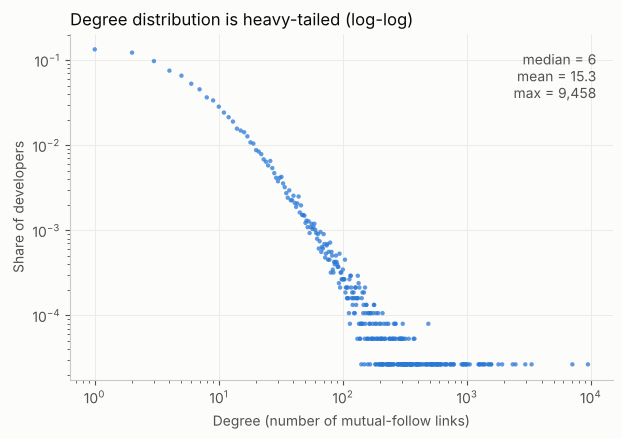

In [23]:
# 1. Degree distribution ------------------------------------------------
d = np.array(list(deg.values()))
vals, counts = np.unique(d, return_counts=True)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(vals, counts / counts.sum(), s=10, color=METHOD_COLOR["CN"], alpha=.75, edgecolor="none")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Degree (number of mutual-follow links)"); ax.set_ylabel("Share of developers")
ax.set_title("Degree distribution is heavy-tailed (log-log)", loc="left")
ax.annotate(f"median = {int(np.median(d))}\nmean = {d.mean():.1f}\nmax = {d.max():,}",
            xy=(.97, .95), xycoords="axes fraction", ha="right", va="top", color=INK2)
style(ax, "both")
save(fig, "01_degree_distribution")

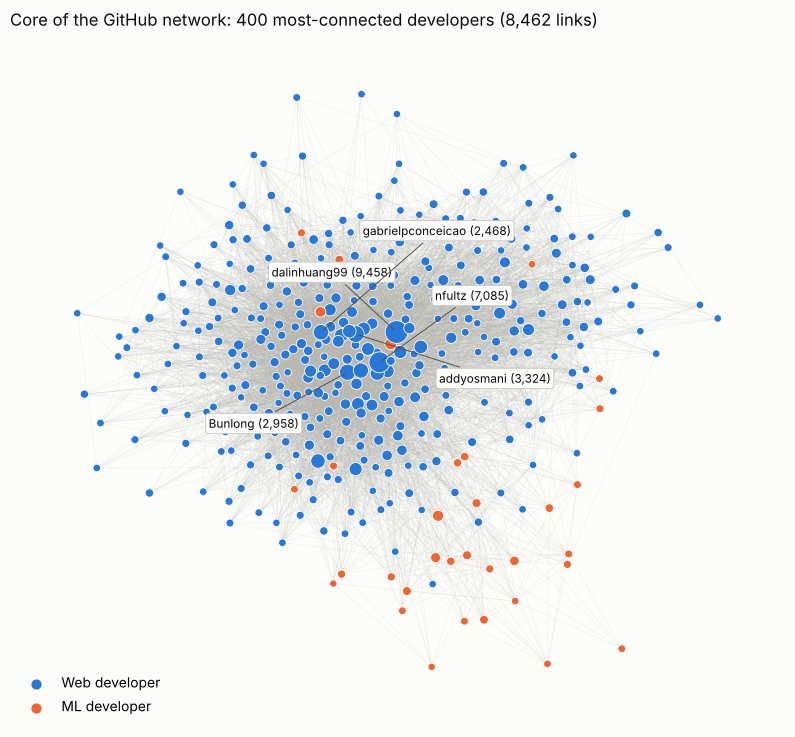

In [24]:
# 2. Network overview: 400 highest-degree developers -------------------
top = sorted(deg, key=deg.get, reverse=True)[:400]
H = G.subgraph(top).copy()
pos = nx.spring_layout(H, seed=7, k=.35, iterations=80)
fig, ax = plt.subplots(figsize=(10, 9))
nx.draw_networkx_edges(H, pos, ax=ax, edge_color="#b8b7b0", width=.15, alpha=.5)
sizes = np.array([deg[n] for n in H])
nx.draw_networkx_nodes(H, pos, ax=ax, node_size=8 + 260 * (sizes / sizes.max()) ** .6,
                       node_color=[COMM_COLOR[H.nodes[n]["community"]] for n in H],
                       edgecolors=SURF, linewidths=.6)
for i, n in enumerate(sorted(H, key=deg.get, reverse=True)[:5]):
    off = [(-90, 40), (40, 45), (60, -35), (-100, -40), (30, 70)][i]
    ax.annotate(f"{H.nodes[n]['name']} ({deg[n]:,})", pos[n], xytext=off, textcoords="offset points",
                fontsize=8.5, color=INK, bbox=dict(boxstyle="round,pad=.25", fc=SURF, ec=AXIS, lw=.6),
                arrowprops=dict(arrowstyle="-", color=INK2, lw=.7))
for c, lab in (("web", "Web developer"), ("ml", "ML developer")):
    ax.scatter([], [], color=COMM_COLOR[c], label=lab, s=40)
ax.legend(frameon=False, loc="lower left")
ax.set_title(f"Core of the GitHub network: 400 most-connected developers ({H.number_of_edges():,} links)", loc="left")
ax.axis("off")
save(fig, "02_network_core_overview")

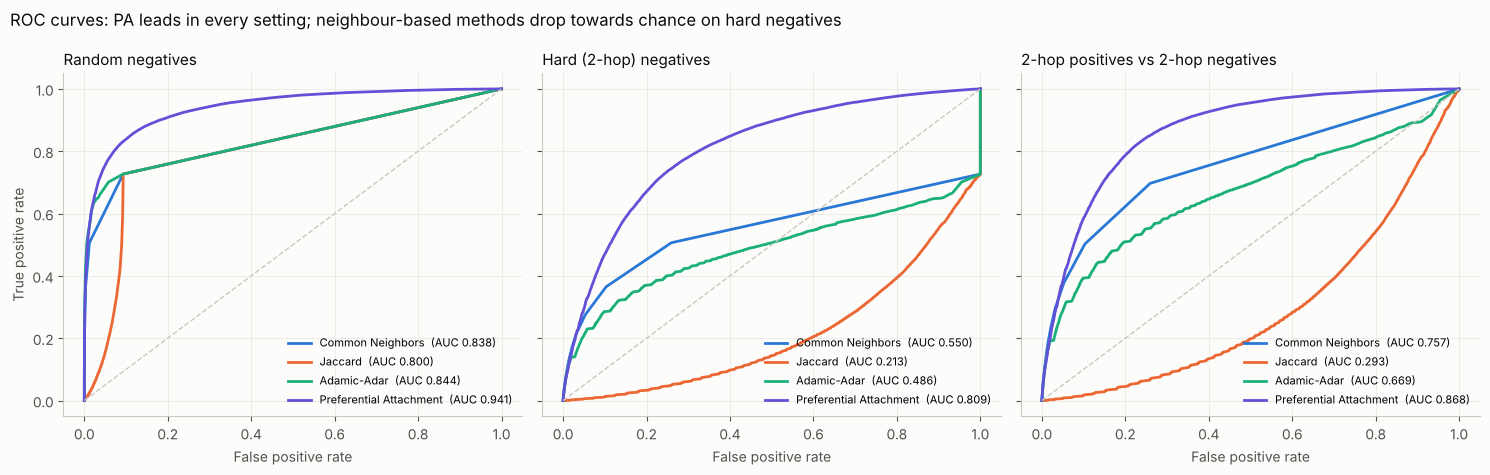

In [25]:
# 3. ROC curves, 3 settings ---------------------------------------------
curves = np.load(f"{RES}/curves.npy", allow_pickle=True).item()
metrics = pd.read_csv(f"{RES}/evaluation_metrics.csv")
settings = [("random", "Random negatives"), ("hard", "Hard (2-hop) negatives"),
            ("twohop", "2-hop positives vs 2-hop negatives")]
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, (key, title) in zip(axs, settings):
    for m in METHODS:
        c = curves[key][m]
        auc = metrics[(metrics.setting == title) & (metrics.method == m)].ROC_AUC.iloc[0]
        ax.plot(c["fpr"], c["tpr"], color=METHOD_COLOR[m], lw=2, label=f"{METHOD_NAME[m]}  (AUC {auc:.3f})")
    ax.plot([0, 1], [0, 1], ls="--", color=AXIS, lw=1)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("False positive rate")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    style(ax, "both")
axs[0].set_ylabel("True positive rate")
fig.suptitle("ROC curves: PA leads in every setting; neighbour-based methods drop towards chance on hard negatives",
             x=.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
save(fig, "03_roc_curves")

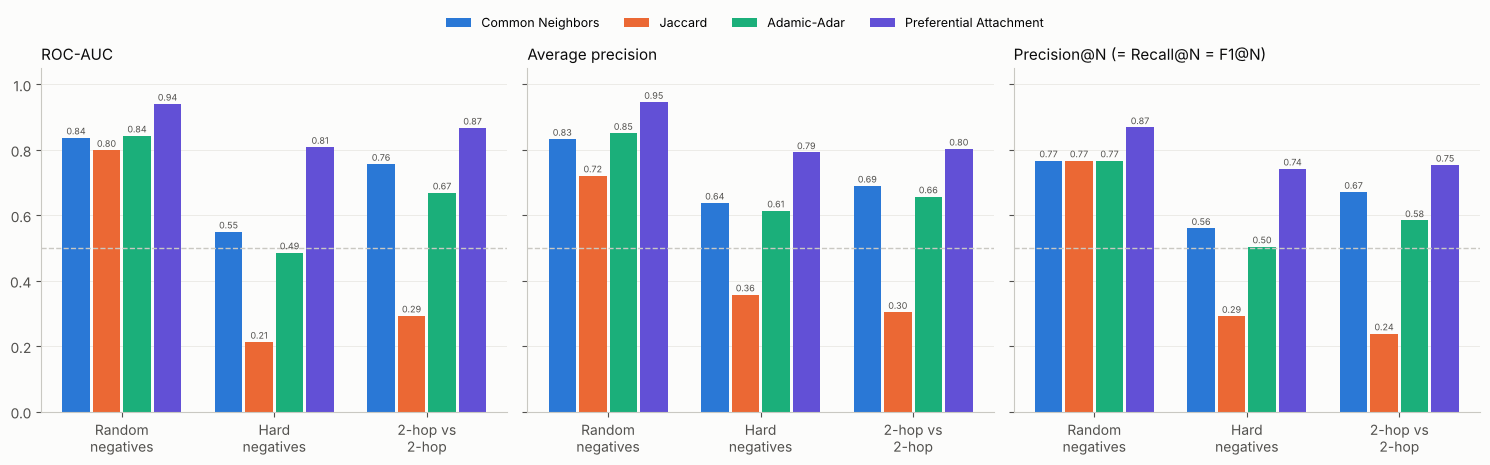

In [26]:
# 4. Metric comparison (grouped bars) ----------------------------------
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, metric, title in zip(axs, ["ROC_AUC", "AvgPrecision", "P@N"],
                             ["ROC-AUC", "Average precision", "Precision@N (= Recall@N = F1@N)"]):
    x = np.arange(len(settings))
    for i, m in enumerate(METHODS):
        v = [metrics[(metrics.setting == t) & (metrics.method == m)][metric].iloc[0] for _, t in settings]
        b = ax.bar(x + (i - 1.5) * .2, v, .18, color=METHOD_COLOR[m], label=METHOD_NAME[m])
        for xi, vi in zip(x + (i - 1.5) * .2, v):
            ax.text(xi, vi + .01, f"{vi:.2f}", ha="center", fontsize=6.5, color=INK2)
    ax.set_xticks(x, ["Random\nnegatives", "Hard\nnegatives", "2-hop vs\n2-hop"])
    ax.set_title(title, loc="left", fontsize=11)
    ax.axhline(.5, color=AXIS, ls="--", lw=1)
    ax.set_ylim(0, 1.05)
    style(ax)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, frameon=False, fontsize=9, loc="upper center", ncol=4, bbox_to_anchor=(.5, 1.06))
fig.tight_layout()
save(fig, "04_metric_comparison")

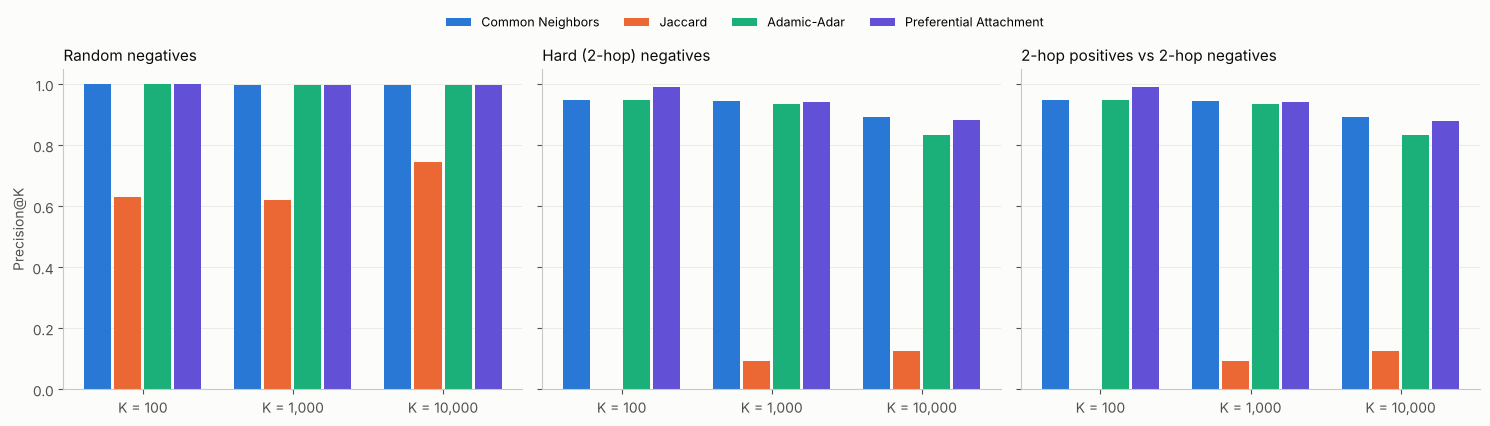

In [27]:
# 5. Precision@K at small K --------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (_, title) in zip(axs, settings):
    x = np.arange(3)
    for i, m in enumerate(METHODS):
        r = metrics[(metrics.setting == title) & (metrics.method == m)].iloc[0]
        ax.bar(x + (i - 1.5) * .2, [r["P@100"], r["P@1000"], r["P@10000"]], .18,
               color=METHOD_COLOR[m], label=METHOD_NAME[m])
    ax.set_xticks(x, ["K = 100", "K = 1,000", "K = 10,000"])
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylim(0, 1.05)
    style(ax)
axs[0].set_ylabel("Precision@K")
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, frameon=False, fontsize=9, loc="upper center", ncol=4, bbox_to_anchor=(.5, 1.07))
fig.tight_layout()
save(fig, "05_precision_at_k")

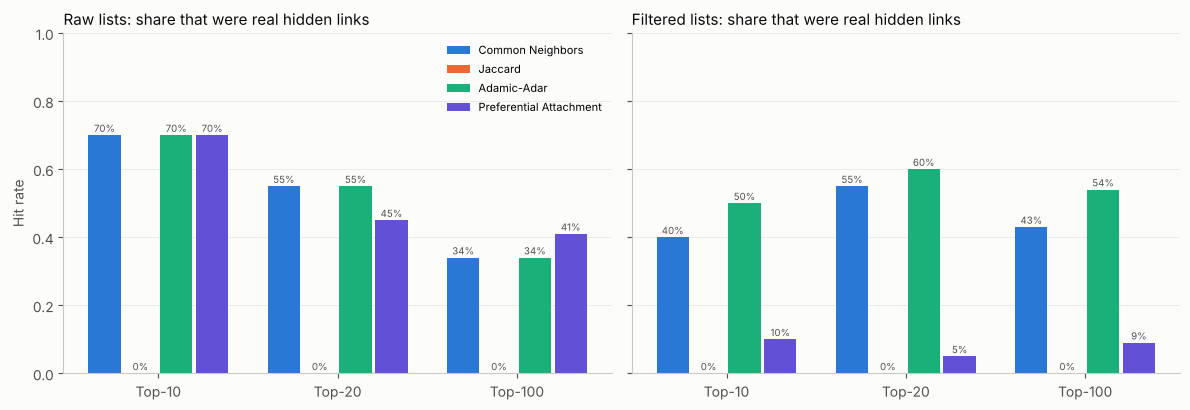

In [28]:
# 6. Back-test of Top-K lists ------------------------------------------
bt = pd.read_csv(f"{RES}/recommendation_backtest.csv")
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, lst in zip(axs, ["raw", "filtered"]):
    x = np.arange(3)
    for i, m in enumerate(METHODS):
        v = [bt[(bt.method == m) & (bt.list == lst) & (bt.K == k)].precision.iloc[0] for k in (10, 20, 100)]
        ax.bar(x + (i - 1.5) * .2, v, .18, color=METHOD_COLOR[m], label=METHOD_NAME[m])
        for xi, vi in zip(x + (i - 1.5) * .2, v):
            ax.text(xi, vi + .01, f"{vi:.0%}", ha="center", fontsize=7, color=INK2)
    ax.set_xticks(x, ["Top-10", "Top-20", "Top-100"])
    ax.set_title(f"{lst.capitalize()} lists: share that were real hidden links", loc="left", fontsize=11)
    ax.set_ylim(0, 1)
    style(ax)
axs[0].set_ylabel("Hit rate")
axs[0].legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()
save(fig, "06_recommendation_backtest")

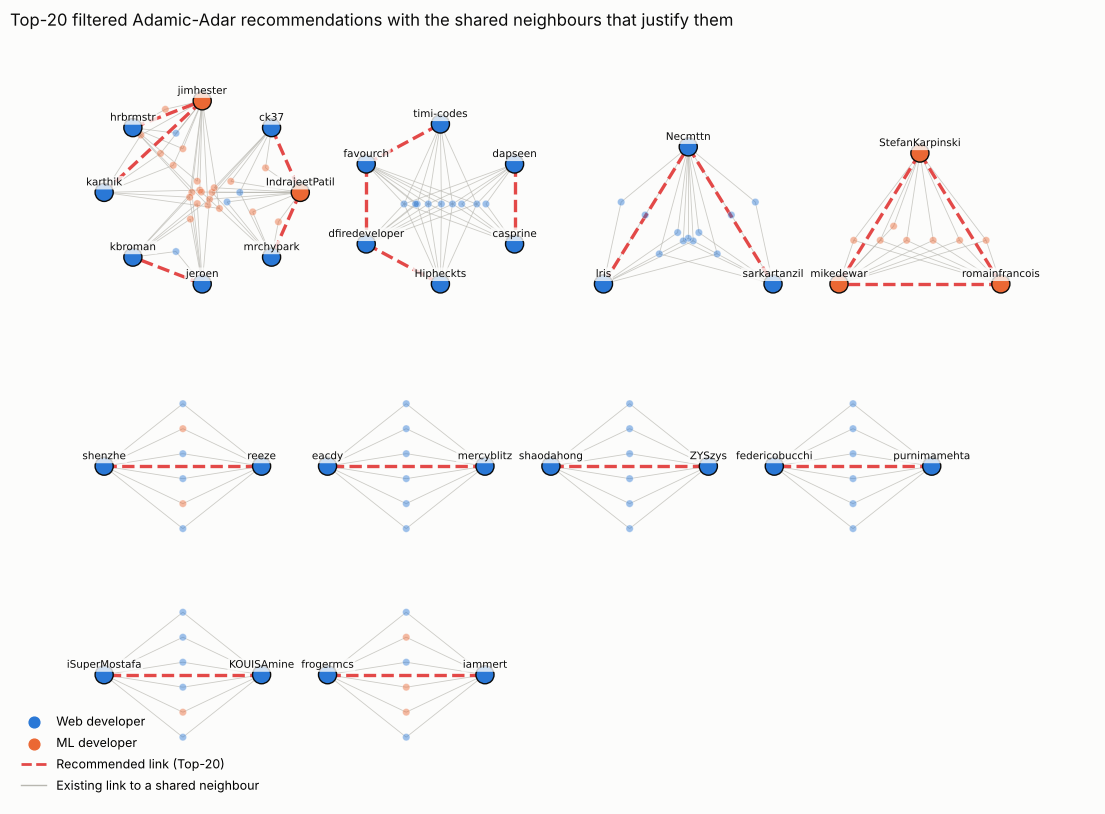

In [29]:
# 7. Recommendation network: filtered Adamic-Adar Top-20 ----------------
def rec_network(top_csv, max_cn_per_pair=6):
    t = pd.read_csv(top_csv)
    R = nx.Graph()
    for r in t.itertuples():
        for n in (r.source, r.target):
            R.add_node(n, name=nodes.loc[n, "name"], community=nodes.loc[n, "community"],
                       degree=deg[n], role="candidate")
    for r in t.itertuples():
        common = sorted(set(G[r.source]) & set(G[r.target]), key=deg.get)[:max_cn_per_pair]
        for w in common:
            if w not in R:
                R.add_node(w, name=nodes.loc[w, "name"], community=nodes.loc[w, "community"],
                           degree=deg[w], role="shared neighbour")
            R.add_edge(r.source, w, kind="existing")
            R.add_edge(r.target, w, kind="existing")
    for r in t.itertuples():
        R.add_edge(r.source, r.target, kind="predicted", rank=int(r.rank),
                   score=round(float(r.AdamicAdar), 3), cn=int(r.CN))
    return R, t


def bridge_layout(sub):
    """Candidates on a circle (recommended pairs side by side), shared neighbours
    stacked between the candidates they connect."""
    cand = [n for n in sub if sub.nodes[n]["role"] == "candidate"]
    P = nx.Graph([(u, v) for u, v, d in sub.edges(data=True) if d.get("kind") == "predicted"])
    order = list(nx.dfs_preorder_nodes(P, cand[0])) if cand[0] in P else cand
    order += [c for c in cand if c not in order]
    pos = {}
    if len(order) == 2:
        pos[order[0]], pos[order[1]] = np.array([-1.0, 0]), np.array([1.0, 0])
    else:
        for i, n in enumerate(order):
            a = 2 * np.pi * i / len(order) + np.pi / 2
            pos[n] = np.array([np.cos(a), np.sin(a)]) * 1.2
    groups = {}
    for w in sub:
        if w in pos:
            continue
        groups.setdefault(frozenset(x for x in sub[w] if x in cand), []).append(w)
    for key, ws in groups.items():
        pts = [pos[k] for k in key]
        centre = np.mean(pts, axis=0)
        if len(key) == 1:                           # private neighbour: push outward
            centre = centre * 1.45
            direction = np.array([-centre[1], centre[0]])
        elif len(key) == 2:                         # between the two candidates, off the dashed line
            seg = pts[1] - pts[0]
            direction = np.array([-seg[1], seg[0]])
            centre = centre * .45
        else:
            centre = centre * .3
            direction = np.array([1.0, 0.0])
        direction = direction / (np.linalg.norm(direction) + 1e-9)
        k = len(ws)
        span = np.linspace(-1, 1, k) * min(.9, .17 * (k - 1)) if k > 1 else np.array([0.0])
        if len(key) == 2 and len(order) > 2:      # keep clear of the dashed line itself
            span = np.where(np.abs(span) < .12, np.sign(span + 1e-9) * .12, span)
        for w, o in zip(ws, span):
            pos[w] = centre + direction * o
    return pos


def tiled_layout(R, cols=4):
    comps = sorted(nx.connected_components(R), key=len, reverse=True)
    pos, x, y, rowh = {}, 0.0, 0.0, 0.0
    for i, c in enumerate(comps):
        p = bridge_layout(R.subgraph(c))
        arr = np.array(list(p.values()))
        arr = (arr - arr.min(0)) / max(np.ptp(arr, 0).max(), 1e-9)
        size = 1.0 + .35 * np.sqrt(len(c) / 10)
        for n, (px, py) in zip(p, arr):
            pos[n] = (x + px * size, y + py * size)
        x += size + .55
        rowh = max(rowh, size)
        if (i + 1) % cols == 0:
            x, y, rowh = 0.0, y - rowh - .55, 0.0
    return pos


R, t = rec_network(f"{RES}/top20_AdamicAdar_filtered.csv")
pos = tiled_layout(R)
fig, ax = plt.subplots(figsize=(14, 10))
ex = [(u, v) for u, v, d in R.edges(data=True) if d["kind"] == "existing"]
pr = [(u, v) for u, v, d in R.edges(data=True) if d["kind"] == "predicted"]
nx.draw_networkx_edges(R, pos, edgelist=ex, edge_color="#b8b7b0", width=.6, alpha=.7, ax=ax)
cand = [n for n in R if R.nodes[n]["role"] == "candidate"]
oth = [n for n in R if R.nodes[n]["role"] != "candidate"]
nx.draw_networkx_nodes(R, pos, nodelist=oth, node_size=28, node_color=[COMM_COLOR[R.nodes[n]["community"]] for n in oth],
                       alpha=.45, edgecolors=SURF, linewidths=.5, ax=ax)
nx.draw_networkx_nodes(R, pos, nodelist=cand, node_size=170, node_color=[COMM_COLOR[R.nodes[n]["community"]] for n in cand],
                       edgecolors=INK, linewidths=1, ax=ax)
pe = nx.draw_networkx_edges(R, pos, edgelist=pr, edge_color=PRED, width=2.4, style="--", ax=ax)
for txt in nx.draw_networkx_labels(R, pos, labels={n: R.nodes[n]["name"] for n in cand}, font_size=7.5,
                                   font_color=INK, verticalalignment="bottom", ax=ax).values():
    txt.set_bbox(dict(boxstyle="round,pad=.15", fc=SURF, ec="none", alpha=.8))
    txt.set_y(txt.get_position()[1] + .04)
for c, lab in (("web", "Web developer"), ("ml", "ML developer")):
    ax.scatter([], [], color=COMM_COLOR[c], s=60, label=lab)
ax.plot([], [], color=PRED, ls="--", lw=2, label="Recommended link (Top-20)")
ax.plot([], [], color="#b8b7b0", lw=1, label="Existing link to a shared neighbour")
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.set_title("Top-20 filtered Adamic-Adar recommendations with the shared neighbours that justify them", loc="left")
ax.axis("off")
save(fig, "07_top20_recommendation_network")

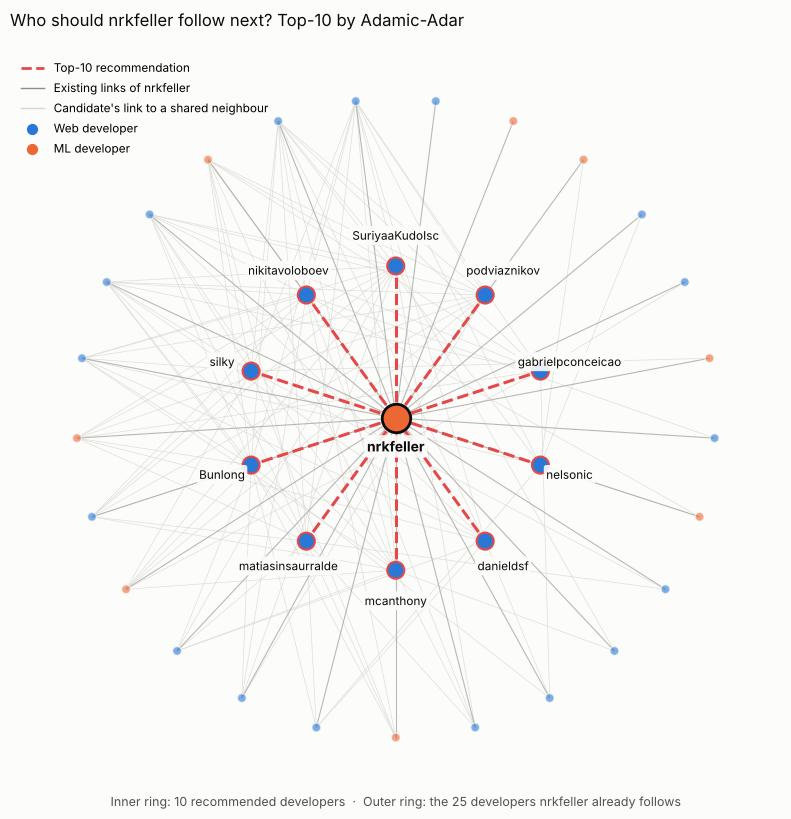

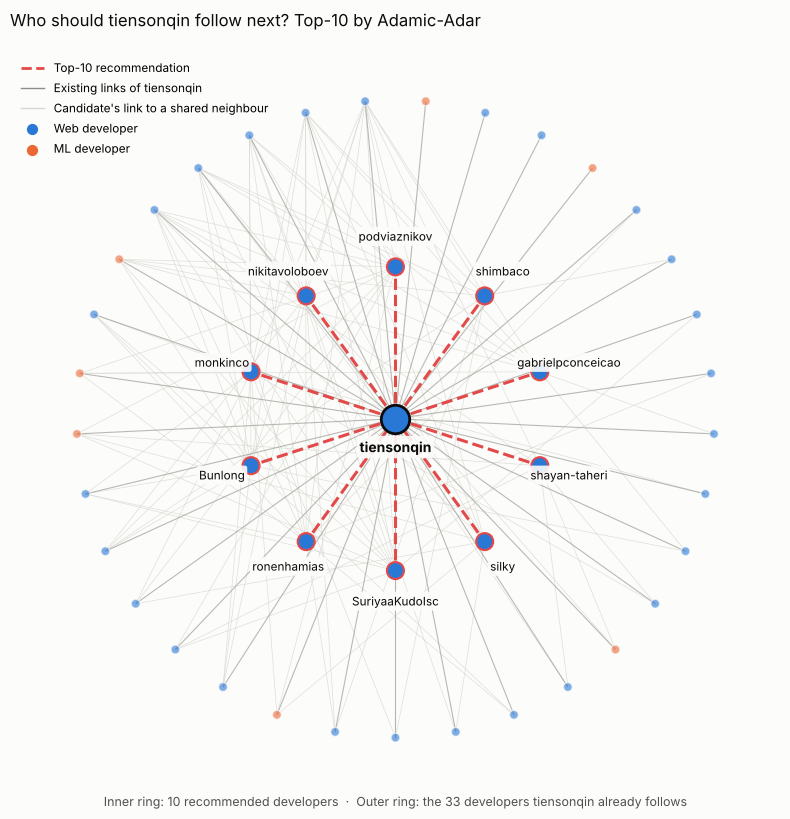

In [30]:
# 8. Ego view for each example developer ---------------------------------
summary = json.load(open(f"{RES}/stage5_summary.json"))
for comm, info in summary["examples"].items():
    dev, name = int(info["id"]), info["name"]
    rec = pd.read_csv(f"{RES}/top10_for_{name}.csv")
    E = nx.Graph()
    E.add_node(dev)
    for n in G[dev]:
        E.add_edge(dev, n, kind="existing")
    for r in rec.itertuples():
        E.add_edge(dev, r.target, kind="predicted")
        for w in set(G[dev]) & set(G[r.target]):
            E.add_edge(r.target, w, kind="support")
    recs_order = list(rec.target)
    nbr_order = sorted(G[dev], key=lambda n: -len(set(G[n]) & set(recs_order)))
    p = {dev: np.array([0.0, 0.0])}
    for i, n in enumerate(recs_order):
        a = 2 * np.pi * i / len(recs_order) + np.pi / 2
        p[n] = np.array([np.cos(a), np.sin(a)]) * 1.0
    for i, n in enumerate(nbr_order):
        a = 2 * np.pi * (i + .5) / len(nbr_order) + np.pi / 2
        p[n] = np.array([np.cos(a), np.sin(a)]) * 2.1
    fig, ax = plt.subplots(figsize=(10, 10))
    for kind, col, wd, st, al in (("support", "#d8d7d0", .5, "-", .8), ("existing", "#a9a8a1", .8, "-", .8),
                                  ("predicted", PRED, 2.2, "--", 1)):
        el = [(u, v) for u, v, d in E.edges(data=True) if d["kind"] == kind]
        nx.draw_networkx_edges(E, p, edgelist=el, edge_color=col, width=wd, style=st, alpha=al, ax=ax)
    recs = set(rec.target)
    nbrs = [n for n in E if n != dev and n not in recs]
    nx.draw_networkx_nodes(E, p, nodelist=nbrs, node_size=40, node_color=[COMM_COLOR[nodes.loc[n, "community"]] for n in nbrs],
                           alpha=.6, edgecolors=SURF, ax=ax)
    nx.draw_networkx_nodes(E, p, nodelist=list(recs), node_size=150, node_color=[COMM_COLOR[nodes.loc[n, "community"]] for n in recs],
                           edgecolors=PRED, linewidths=1.5, ax=ax)
    nx.draw_networkx_nodes(E, p, nodelist=[dev], node_size=420, node_color=COMM_COLOR[comm], edgecolors=INK, linewidths=2, ax=ax)
    for n in recs:
        v = p[n] / np.linalg.norm(p[n])
        ax.annotate(nodes.loc[n, "name"], p[n], xytext=v * 22, textcoords="offset points", ha="center", va="center",
                    fontsize=8.5, color=INK, bbox=dict(boxstyle="round,pad=.2", fc=SURF, ec="none", alpha=.9))
    ax.annotate(name, p[dev], xytext=(0, -24), textcoords="offset points", ha="center", fontsize=10,
                fontweight="bold", color=INK, bbox=dict(boxstyle="round,pad=.2", fc=SURF, ec="none", alpha=.9))
    ax.text(0, -2.55, f"Inner ring: 10 recommended developers  ·  Outer ring: the {len(nbr_order)} developers {name} already follows",
            ha="center", fontsize=9, color=INK2)
    ax.set_aspect("equal")
    ax.plot([], [], color=PRED, ls="--", lw=2, label="Top-10 recommendation")
    ax.plot([], [], color="#8e8d86", lw=1, label=f"Existing links of {name}")
    ax.plot([], [], color="#d8d7d0", lw=1, label="Candidate's link to a shared neighbour")
    for c, lab in (("web", "Web developer"), ("ml", "ML developer")):
        ax.scatter([], [], color=COMM_COLOR[c], s=50, label=lab)
    ax.legend(frameon=False, loc="upper left", fontsize=8.5, bbox_to_anchor=(0, .98))
    ax.set_title(f"Who should {name} follow next? Top-10 by Adamic-Adar", loc="left")
    ax.axis("off")
    save(fig, f"08_ego_recommendations_{name}")

In [31]:
# 9. Cytoscape desktop exports -------------------------------------------
for n in R:
    R.nodes[n]["degree"] = int(R.nodes[n]["degree"])
nx.write_graphml(R, f"{CY}/top20_recommendation_network.graphml")
cyjs = nx.cytoscape_data(R)
for nd in cyjs["elements"]["nodes"]:
    nd["data"]["id"] = str(nd["data"]["id"])
for e in cyjs["elements"]["edges"]:
    e["data"]["source"], e["data"]["target"] = str(e["data"]["source"]), str(e["data"]["target"])
json.dump(cyjs, open(f"{CY}/top20_recommendation_network.cyjs", "w"), indent=1)
pd.DataFrame([{"source": u, "target": v, **d} for u, v, d in R.edges(data=True)]).to_csv(
    f"{CY}/top20_recommendation_edges.csv", index=False)
pd.DataFrame([{"id": n, **d} for n, d in R.nodes(data=True)]).to_csv(f"{CY}/top20_recommendation_nodes.csv", index=False)
print("figures:", sorted(os.listdir(FIG)))
print("recommendation network:", R.number_of_nodes(), "nodes", R.number_of_edges(), "edges")

figures: ['01_degree_distribution.png', '01_degree_distribution.svg', '02_network_core_overview.png', '02_network_core_overview.svg', '03_roc_curves.png', '03_roc_curves.svg', '04_metric_comparison.png', '04_metric_comparison.svg', '05_precision_at_k.png', '05_precision_at_k.svg', '06_recommendation_backtest.png', '06_recommendation_backtest.svg', '07_top20_recommendation_network.png', '07_top20_recommendation_network.svg', '08_ego_recommendations_nrkfeller.png', '08_ego_recommendations_nrkfeller.svg', '08_ego_recommendations_tiensonqin.png', '08_ego_recommendations_tiensonqin.svg']
recommendation network: 120 nodes 231 edges


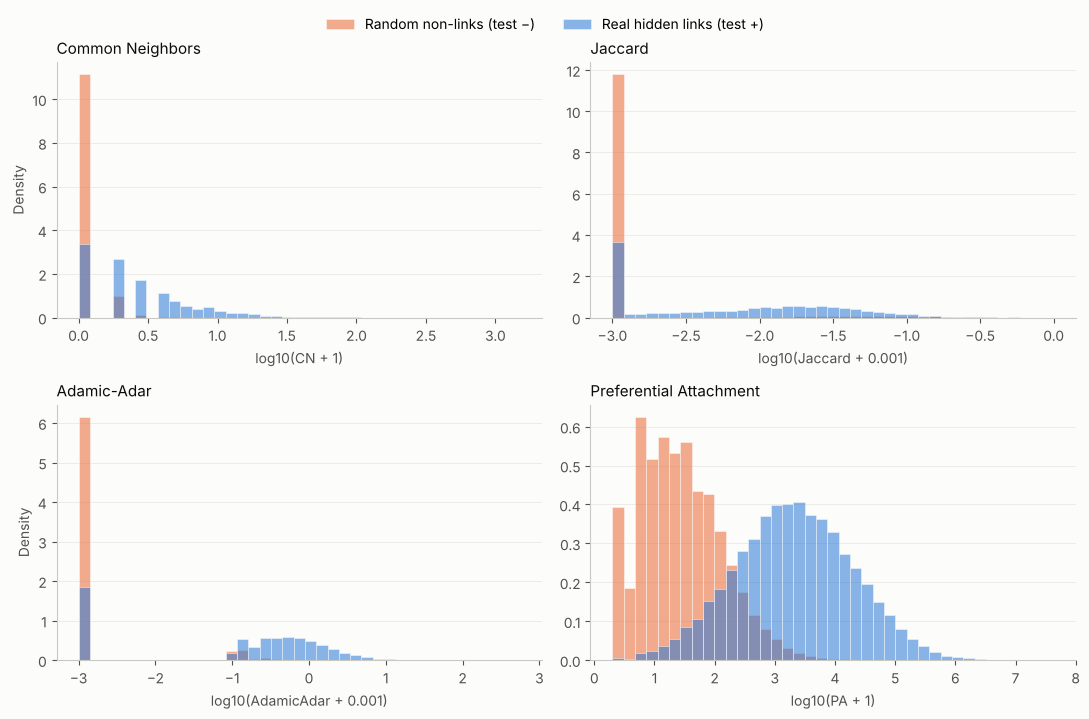

In [32]:
# 0. Score distributions (stage 3) --------------------------------------
s = pd.read_csv(f"{RES}/test_scores.csv")
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for a, m in zip(axs.flat, METHODS):
    off = 1 if m in ("CN", "PA") else 1e-3
    x = np.log10(s[m] + off)
    bins = np.linspace(x.min(), x.max(), 40)
    for lab, col, txt in ((0, "#eb6834", "Random non-links (test −)"), (1, "#2a78d6", "Real hidden links (test +)")):
        a.hist(x[s.label == lab], bins=bins, density=True, alpha=.55, color=col, label=txt, edgecolor=SURF, linewidth=.6)
    a.set_title(METHOD_NAME[m], loc="left", fontsize=11)
    a.set_xlabel(f"log10({m} + {off:g})")
    style(a)
axs[0, 0].set_ylabel("Density"); axs[1, 0].set_ylabel("Density")
h, l = axs[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(.5, 1.03))
fig.tight_layout()
save(fig, "00_score_distributions")

In [33]:
# 10. Interactive Cytoscape.js page ----------------------------------------
def cy_elements(Rg, pred_key):
    els = []
    for n, d in Rg.nodes(data=True):
        els.append({"data": {"id": str(n), "label": d["name"], "community": d["community"],
                             "degree": int(d["degree"]), "role": d["role"]}})
    for u, v, d in Rg.edges(data=True):
        e = {"id": f"{u}-{v}", "source": str(u), "target": str(v), "kind": d["kind"]}
        if d["kind"] == "predicted":
            e.update(rank=d["rank"], cn=d["cn"], score=d["score"])
        els.append({"data": e})
    return els


views = {}
for m in METHODS:
    for lst in ("filtered", "raw"):
        Rm, tm = rec_network(f"{RES}/top20_{m}_{lst}.csv", max_cn_per_pair=4)
        for u, v, d in Rm.edges(data=True):
            if d["kind"] == "predicted":
                row = tm[((tm.source == u) & (tm.target == v)) | ((tm.source == v) & (tm.target == u))].iloc[0]
                d["score"] = round(float(row[m]), 4)
        views[f"{m}|{lst}"] = cy_elements(Rm, m)
json.dump(views, open(f"{CY}/views.json", "w"))

In [34]:
# Interactive Cytoscape.js explorer (this notebook version loads Cytoscape.js from the cdnjs CDN;
# the copy in 3_Network_Visualizations embeds the library so it also works offline)
html = open("src/explorer_template.html").read().replace("__VIEWS__", json.dumps(views))
open("outputs/figures/09_interactive_recommendation_explorer.html", "w").write(html)
print("written outputs/figures/09_interactive_recommendation_explorer.html")

written outputs/figures/09_interactive_recommendation_explorer.html


## Conclusions
* All four heuristics look strong on random negatives (ROC-AUC 0.80–0.94), but that benchmark is easy.
* On hard (2-hop) negatives the ranking changes sharply: **Preferential Attachment stays strongest**
  (AUC ≈ 0.81–0.87), CN and Adamic-Adar fall towards chance, and Jaccard is *worse than random*, because in this
  hub-dominated network Jaccard rewards low-degree pairs that share a single celebrity.
* For actual recommendation lists, **filtered Adamic-Adar** gives the best and most explainable Top-K
  (60% of its back-tested Top-20 were real hidden links), while raw PA only recommends hub-to-hub links.